## 1. Imports

In [1]:
# Standard libraries for data manipulation, visualization, and modeling
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

import warnings
warnings.filterwarnings('ignore')

## 2. Load Data

In [2]:
# Load the dataset and inspect its shape and first rows
df = pd.read_csv('../data/ds_salaries.csv')
print(df.shape)
df.head()

(3755, 9)


,work_year,experience_level,employment_type,job_title,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,CA,100,CA,M


## 3. Select Features & Target

In [3]:
# Choose the input features and the salary column as the prediction target
FEATURES = ['job_title', 'experience_level', 'employment_type', 'company_size',
            'company_location', 'work_year', 'remote_ratio']
TARGET = 'salary_in_usd'

data = df[FEATURES + [TARGET]].copy()
print(data.shape)
data.head()

(3755, 8)


,job_title,experience_level,employment_type,company_size,company_location,work_year,remote_ratio,salary_in_usd
0,Principal Data Scientist,SE,FT,L,ES,2023,100,85847
1,ML Engineer,MI,CT,S,US,2023,100,30000
2,ML Engineer,MI,CT,S,US,2023,100,25500
3,Data Scientist,SE,FT,M,CA,2023,100,175000
4,Data Scientist,SE,FT,M,CA,2023,100,120000


## 4. Preprocessing

### 4.1 Drop Duplicates

In [4]:
# Remove identical rows to avoid data leakage and biased evaluation
before = len(data)
data = data.drop_duplicates()
print(f'Removed {before - len(data)} duplicates. Remaining rows: {len(data)}')

Removed 1172 duplicates. Remaining rows: 2583


### 4.2 Filter to Selected Job Titles & Locations

In [5]:
# Keep only the most common job titles and group rare locations under "Other"
ALLOWED_JOBS = ['Data Scientist', 'ML Engineer', 'Data Engineer',
                'Data Analyst', 'Research Scientist']

ALLOWED_LOCATIONS = ['US', 'GB', 'CA', 'DE', 'IN', 'FR', 'AU']

data = data[data['job_title'].isin(ALLOWED_JOBS)]
data['company_location'] = data['company_location'].apply(
    lambda x: x if x in ALLOWED_LOCATIONS else 'Other'
)
print(data.shape)
data['job_title'].value_counts()

(1631, 8)


job_title
Data Engineer         598
Data Scientist        538
Data Analyst          396
Research Scientist     65
ML Engineer            34
Name: count, dtype: int64

### 4.3 Check Missing Values

In [6]:
# Ensure there are no nulls before modeling
data.isnull().sum()

job_title           0
experience_level    0
employment_type     0
company_size        0
company_location    0
work_year           0
remote_ratio        0
salary_in_usd       0
dtype: int64

### 4.4 Define Categorical & Numeric Columns

In [7]:
CAT_COLS = ['job_title', 'experience_level', 'employment_type',
            'company_size', 'company_location']
NUM_COLS = ['work_year', 'remote_ratio']

### 4.5 Train / Test Split

In [8]:
# Split data into 80% training and 20% testing with a fixed random seed
X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')

Train: (1304, 7), Test: (327, 7)


### 4.6 Preprocessor (OneHotEncoder + StandardScaler)

In [9]:
# Encode categorical columns and scale numeric columns
preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
    ('num', StandardScaler(), NUM_COLS)
])

## 5. Exploratory Data Analysis

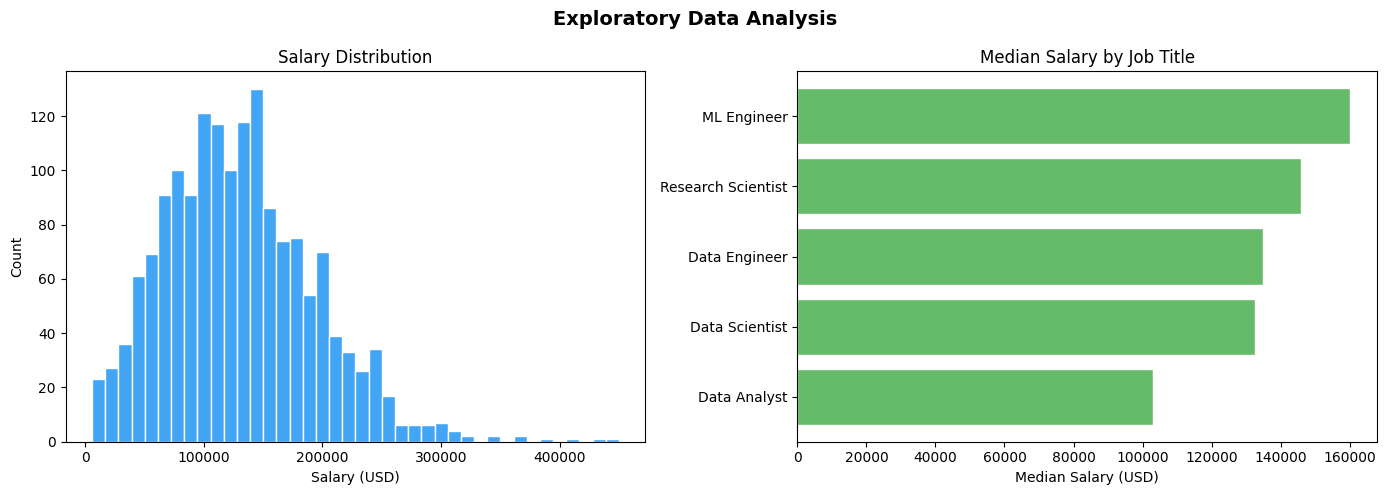

In [10]:
# Quick look at salary distribution and average salary per job title

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Salary distribution
axes[0].hist(data[TARGET], bins=40, color='#42A5F5', edgecolor='white')
axes[0].set_title('Salary Distribution')
axes[0].set_xlabel('Salary (USD)')
axes[0].set_ylabel('Count')

# Average salary by job title
avg_salary = data.groupby('job_title')[TARGET].median().sort_values()
axes[1].barh(avg_salary.index, avg_salary.values, color='#66BB6A', edgecolor='white')
axes[1].set_title('Median Salary by Job Title')
axes[1].set_xlabel('Median Salary (USD)')

plt.suptitle('Exploratory Data Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Evaluation Helper

In [11]:
# Trains the model, prints metrics, and returns results for comparison
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    preds = model.predict(X_te)
    mae  = mean_absolute_error(y_te, preds)
    rmse = np.sqrt(mean_squared_error(y_te, preds))
    r2   = r2_score(y_te, preds)
    print(f'{name:40s}  MAE={mae:>10,.0f}  RMSE={rmse:>10,.0f}  R2={r2:.4f}')
    return {'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'pipeline': model}

results = []

## 7. Model Training

### 7.1 Linear Regression

In [12]:
pipe_lr = Pipeline([('pre', preprocessor), ('model', LinearRegression())])
results.append(evaluate('Linear Regression', pipe_lr, X_train, y_train, X_test, y_test))

Linear Regression                         MAE=    36,535  RMSE=    47,844  R2=0.3961


### 7.2 Polynomial Regression (degree=2)

In [13]:
pipe_poly = Pipeline([
    ('pre', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LinearRegression())
])
results.append(evaluate('Polynomial Regression (d=2)', pipe_poly, X_train, y_train, X_test, y_test))

Polynomial Regression (d=2)               MAE=    39,071  RMSE=    53,293  R2=0.2507


### 7.3 Ridge Regression

In [14]:
pipe_ridge = Pipeline([('pre', preprocessor), ('model', Ridge(alpha=10.0))])
results.append(evaluate('Ridge Regression', pipe_ridge, X_train, y_train, X_test, y_test))

Ridge Regression                          MAE=    36,388  RMSE=    47,627  R2=0.4016


### 7.4 Lasso Regression

In [15]:
pipe_lasso = Pipeline([('pre', preprocessor), ('model', Lasso(alpha=100.0, max_iter=10000))])
results.append(evaluate('Lasso Regression', pipe_lasso, X_train, y_train, X_test, y_test))

Lasso Regression                          MAE=    36,425  RMSE=    47,723  R2=0.3992


### 7.5 Support Vector Regression

In [16]:
pipe_svr = Pipeline([('pre', preprocessor), ('model', SVR(kernel='rbf', C=100000, epsilon=5000))])
results.append(evaluate('SVR (RBF)', pipe_svr, X_train, y_train, X_test, y_test))

SVR (RBF)                                 MAE=    36,827  RMSE=    49,348  R2=0.3576


### 7.6 Decision Tree Regression

In [17]:
pipe_dt = Pipeline([('pre', preprocessor), ('model', DecisionTreeRegressor(max_depth=6, random_state=42))])
results.append(evaluate('Decision Tree', pipe_dt, X_train, y_train, X_test, y_test))

Decision Tree                             MAE=    37,413  RMSE=    50,475  R2=0.3279


### 7.7 Random Forest Regression

In [18]:
pipe_rf = Pipeline([('pre', preprocessor), ('model', RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1))])
results.append(evaluate('Random Forest', pipe_rf, X_train, y_train, X_test, y_test))

Random Forest                             MAE=    37,978  RMSE=    50,510  R2=0.3269


## 8. Model Comparison

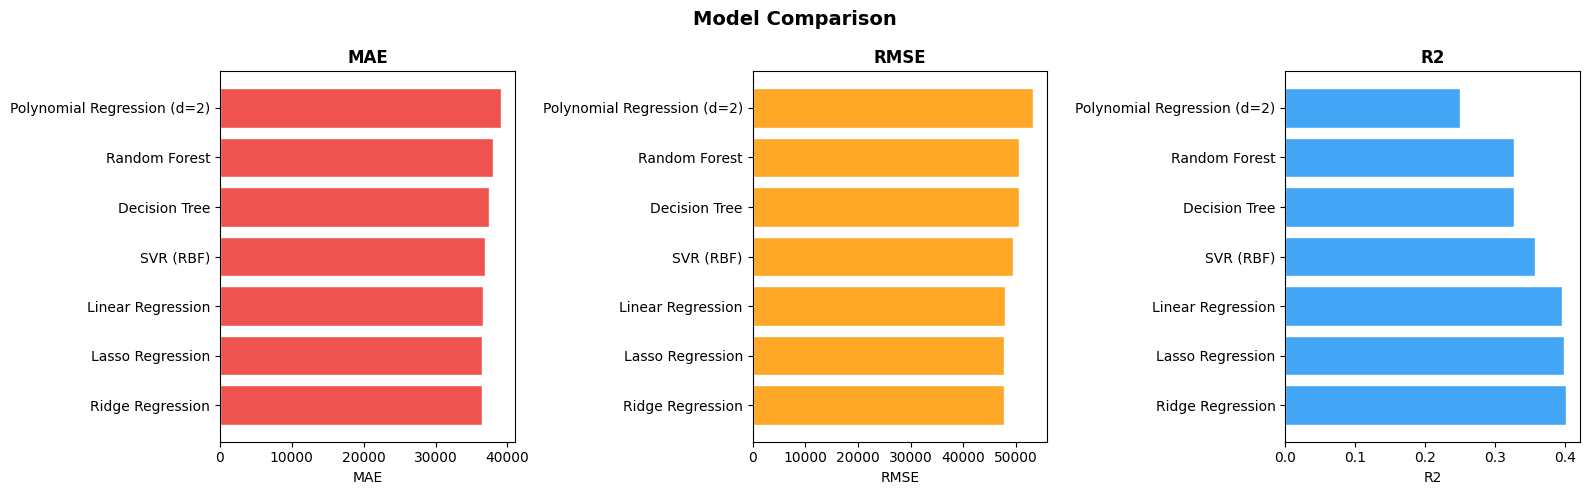

In [19]:
df_res = pd.DataFrame([{k: v for k, v in r.items() if k != 'pipeline'} for r in results])
df_res = df_res.sort_values('R2', ascending=False).reset_index(drop=True)
df_res

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = ['MAE', 'RMSE', 'R2']
colors  = ['#EF5350', '#FFA726', '#42A5F5']

for ax, metric, color in zip(axes, metrics, colors):
    ascending = metric != 'R2'
    plot_df = df_res.sort_values(metric, ascending=ascending)
    ax.barh(plot_df['Model'], plot_df[metric], color=color, edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_xlabel(metric)

plt.suptitle('Model Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Best Model Analysis

### 9.1 Save Best Model

In [20]:
best_name = df_res.iloc[0]['Model']
best_pipe = next(r['pipeline'] for r in results if r['Model'] == best_name)
print(f'Best model: {best_name}')

joblib.dump(best_pipe, 'best_model.pkl')
print('Saved to best_model.pkl')

Best model: Ridge Regression
Saved to best_model.pkl


### 9.2 Residual Plot

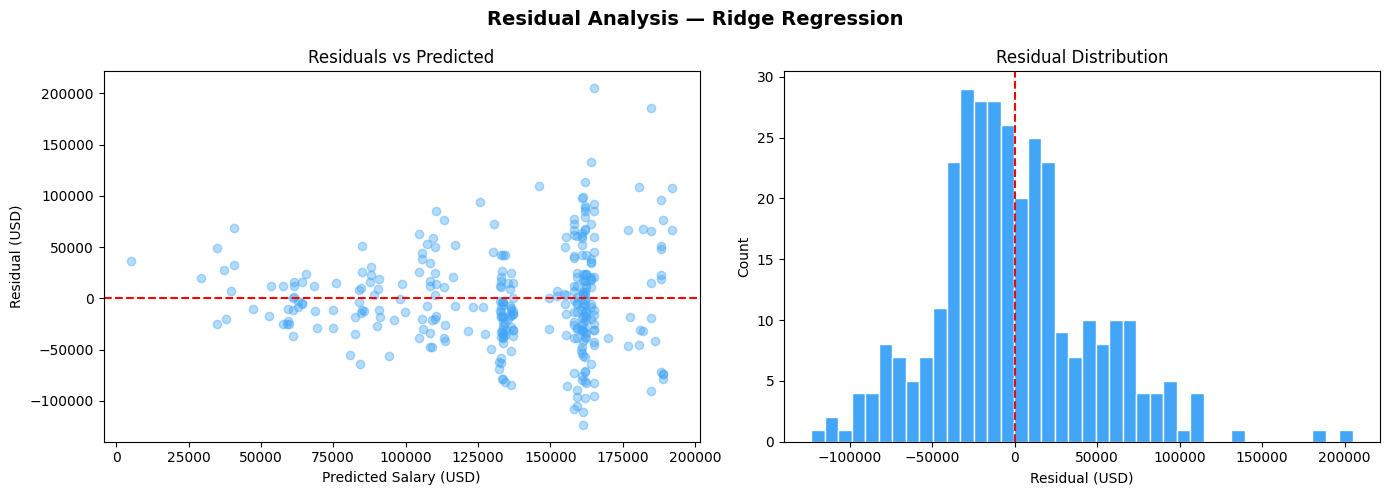

In [21]:
# Check if errors are randomly distributed (no pattern = good model)
best_preds = best_pipe.predict(X_test)
residuals = y_test.values - best_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Predicted
axes[0].scatter(best_preds, residuals, alpha=0.4, color='#42A5F5')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_xlabel('Predicted Salary (USD)')
axes[0].set_ylabel('Residual (USD)')
axes[0].set_title('Residuals vs Predicted')

# Residual distribution
axes[1].hist(residuals, bins=40, color='#42A5F5', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Residual (USD)')
axes[1].set_ylabel('Count')
axes[1].set_title('Residual Distribution')

plt.suptitle(f'Residual Analysis — {best_name}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 9.3 Actual vs Predicted Plot

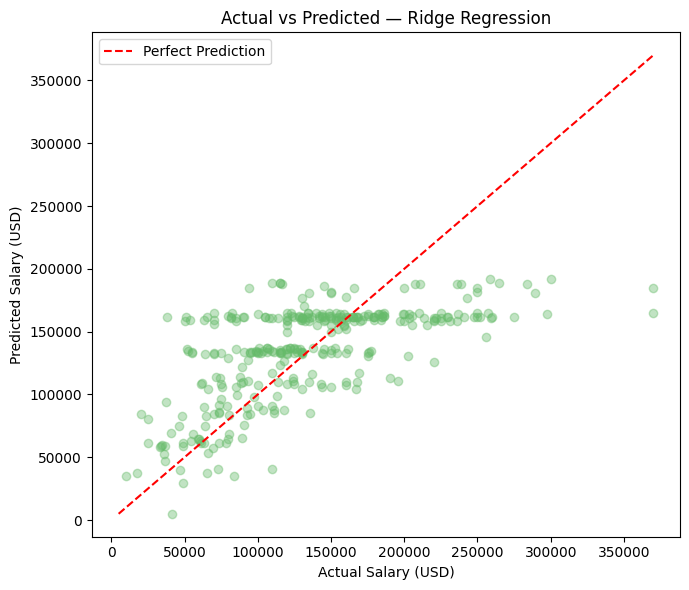

In [22]:
# Ideal model = all points on the diagonal line
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, best_preds, alpha=0.4, color='#66BB6A')
min_val = min(y_test.min(), best_preds.min())
max_val = max(y_test.max(), best_preds.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Perfect Prediction')
ax.set_xlabel('Actual Salary (USD)')
ax.set_ylabel('Predicted Salary (USD)')
ax.set_title(f'Actual vs Predicted — {best_name}')
ax.legend()
plt.tight_layout()
plt.show()

### 9.4 Accuracy Within Tolerance Bands

In [23]:
# Percentage of predictions within ±10%, ±15%, and ±20% of the actual salary
print("Prediction Accuracy Within Tolerance:")
for tol in [0.10, 0.15, 0.20]:
    acc = np.mean(np.abs(best_preds - y_test.values) / y_test.values <= tol)
    print(f"  Within +/-{int(tol*100)}%: {acc:.2%}")

Prediction Accuracy Within Tolerance:
  Within +/-10%: 22.32%
  Within +/-15%: 33.33%
  Within +/-20%: 43.12%


In [24]:
print(df_res[['Model', 'R2', 'MAE', 'RMSE']].to_string(index=False))

                      Model       R2          MAE         RMSE
           Ridge Regression 0.401592 36388.426441 47626.611082
           Lasso Regression 0.399172 36425.468992 47722.853396
          Linear Regression 0.396106 36535.100693 47844.439931
                  SVR (RBF) 0.357564 36826.913722 49347.589120
              Decision Tree 0.327880 37412.589235 50474.800452
              Random Forest 0.326935 37978.165165 50510.258849
Polynomial Regression (d=2) 0.250726 39071.240907 53293.167812
